<a href="https://colab.research.google.com/github/omeruslusoy/brfss-ruhsal-sikinti/blob/main/02_modelleme.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Veri Madenciliği Projesi – Notebook 2: Öznitelik Mühendisliği, Öznitelik Seçimi ve Modelleme
**Öğrenci:** Ömer Uslusoy (26221004006)

**Girdi:** Notebook 1'de temizlenip ayrılan eğitim (279.739) ve test (69.935) kümeleri.

**Akış:** (1) öznitelik mühendisliği → (2) ön işleme hattı (eksik doldurma, kodlama, ölçekleme) → (3) baz çizgi modeller → (4) öznitelik seçimi yöntemlerinin karşılaştırılması → (5) kNN hiperparametre ayarı → (6) test kümesinde tek seferlik değerlendirme.

**Kural:** Veriden öğrenilen her şey (doldurma değerleri, ölçekleme, öznitelik seçimi, hiperparametreler) yalnızca eğitim kümesinden ve çapraz doğrulama katlarının içinde öğrenilir; test kümesi yalnızca en sonda bir kez kullanılır. Değerlendirme ölçütleri: F1 ve ROC-AUC (sınıf dengesizliği nedeniyle doğruluk yanıltıcıdır).

In [1]:
from google.colab import drive
drive.mount('/content/drive')

import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

RANDOM_STATE = 42

yol = glob.glob('/content/drive/MyDrive/**/brfss_egitim.parquet', recursive=True)[0]
klasor = yol.rsplit('/', 1)[0]
egitim = pd.read_parquet(klasor + '/brfss_egitim.parquet')
test = pd.read_parquet(klasor + '/brfss_test.parquet')
print('Eğitim:', egitim.shape, '| Test:', test.shape)

Mounted at /content/drive
Eğitim: (279739, 41) | Test: (69935, 41)


## 1. Öznitelik mühendisliği
Notebook 1'deki bulgulara dayanarak şu dönüşümler yapılmıştır:
- **Çocuk sayısı 4'te kırpıldı** (0/1/2/3/4+): değerlerin neredeyse tamamı 0-4 arasındadır; 10'un üzerindeki olası hatalı değerler etkisizleşir.
- **İdeal uykudan sapma (UYKU_SAPMA = |uyku − 7,5|):** uyku ile sıkıntı arasındaki ilişki U biçimlidir; hem çok kısa hem çok uzun uyku risklidir. Doğrusal bir model bu ilişkiyi ham uyku saatiyle yakalayamaz, sapma değişkeniyle yakalayabilir.
- **BMI kategorileri (Dünya Sağlık Örgütü):** zayıf, normal, fazla kilolu, obez I-II-III. BMI ile ilişki de U biçimli olduğundan kategoriler nominal olarak kodlanacaktır.
- **Eyalet → bölge:** 50 değerli eyalet değişkeni (one-hot ile 50 sütun) ABD nüfus sayım bölgelerine (Kuzeydoğu, Orta Batı, Güney, Batı) ve "ABD toprakları"na (Guam, Porto Riko) indirgenmiştir.
- **Diyabet:** çok nadir olan "yalnızca gebelikte" kategorisi (%0,8) "yok" ile birleştirilmiştir.
- **İki eksiklik göstergesi** (doldurmadan önce): GELIR_EKSIK (gelir yanıtsız) ve KISMI_GORUSME (uyku-tütün-alkol bloğunun tamamı eksik).
- **İkili değişkenler 1 = evet, 0 = hayır** olarak yeniden kodlanmıştır.

Bu dönüşümler veriden öğrenilmeyen sabit kurallar olduğu için eğitim ve test kümelerine aynı fonksiyonla uygulanmıştır; veri sızıntısı oluşmaz.

In [2]:
# Eyalet FIPS kodu → ABD nüfus sayım bölgesi (1 Kuzeydoğu, 2 Orta Batı, 3 Güney, 4 Batı, 5 ABD toprakları)
BOLGE_LISTESI = {
    1: [9, 23, 25, 33, 34, 36, 42, 44, 50],
    2: [17, 18, 19, 20, 26, 27, 29, 31, 38, 39, 46, 55],
    3: [1, 5, 10, 11, 12, 13, 21, 22, 24, 28, 37, 40, 45, 47, 48, 51, 54],
    4: [2, 4, 6, 8, 15, 16, 30, 32, 35, 41, 49, 53, 56],
    5: [66, 72, 78],
}
EYALET_BOLGE = {fips: bolge for bolge, liste in BOLGE_LISTESI.items() for fips in liste}

# İkili değişkenlerde "evet" kodu (2025 codebook'undan)
IKILI_KOD = {'SEXVAR': 2, 'VETERAN3': 1, '_URBSTAT': 1, '_HLTHPL2': 1, 'MEDCOST1': 1, '_TOTINDA': 1,
             '_CURECI3': 2, '_RFBING6': 2, '_RFDRHV9': 2, '_MICHD': 1, 'CVDSTRK3': 1, 'CHCCOPD3': 1,
             'CHCKDNY2': 1, 'HAVARTH4': 1, 'CHCSCNC1': 1, 'CHCOCNC1': 1, 'DEAF': 1, 'BLIND': 1,
             'DIFFWALK': 1, 'DIFFDRES': 1}

def oznitelik_uret(veri):
    d = veri.copy()
    d['CHILDREN'] = d['CHILDREN'].clip(upper=4)
    d['UYKU_SAPMA'] = (d['SLEPTIM1'] - 7.5).abs()
    d['BMI_KAT'] = pd.cut(d['_BMI5'], [0, 18.5, 25, 30, 35, 40, 200], right=False,
                          labels=[1, 2, 3, 4, 5, 6]).astype(float)
    d['BOLGE'] = d['_STATE'].map(EYALET_BOLGE)
    d['DIABETE4'] = d['DIABETE4'].replace(2, 3)
    # Eksiklik göstergeleri – doldurmadan ÖNCE hesaplanmalı
    d['GELIR_EKSIK'] = d['_INCOMG1'].isna().astype(int)
    blok = ['SLEPTIM1', '_SMOKER3', '_CURECI3', 'ALKOL_GUN', '_RFBING6', '_RFDRHV9']
    d['KISMI_GORUSME'] = d[blok].isna().all(axis=1).astype(int)
    # İkilileri 1 = evet / 0 = hayır yap (eksikler eksik kalır)
    for s, kod in IKILI_KOD.items():
        d[s] = (d[s] == kod).astype(float).where(d[s].notna())
    return d.drop(columns=['_STATE', 'SEQNO'])

egitim_oz = oznitelik_uret(egitim)
test_oz = oznitelik_uret(test)

# Öznitelik grupları (ön işlemede her gruba farklı işlem uygulanacak)
SAYISAL = ['_AGE80', 'CHILDREN', 'SLEPTIM1', 'UYKU_SAPMA', 'PHYSHLTH', '_BMI5', 'ALKOL_GUN']
SIRALI  = ['GENHLTH', '_EDUCAG', '_INCOMG1', 'CHECKUP1', '_SMOKER3']
IKILI   = list(IKILI_KOD) + ['GELIR_EKSIK', 'KISMI_GORUSME']
NOMINAL = ['_RACEGR3', 'MARITAL', 'EMPLOY1', 'RENTHOM1', 'PERSDOC3', '_ASTHMS1', 'DIABETE4', 'BOLGE', 'BMI_KAT']
OZNITELIKLER = SAYISAL + SIRALI + IKILI + NOMINAL

print('Eğitim:', egitim_oz.shape, '| Test:', test_oz.shape)
print(f'Öznitelik sayısı: {len(OZNITELIKLER)} (sayısal {len(SAYISAL)}, sıralı {len(SIRALI)}, '
      f'ikili {len(IKILI)}, nominal {len(NOMINAL)})')
eksik_kalan = set(egitim_oz.columns) - set(OZNITELIKLER) - {'hedef'}
print('Listede olmayan sütun:', eksik_kalan if eksik_kalan else 'yok')

Eğitim: (279739, 44) | Test: (69935, 44)
Öznitelik sayısı: 43 (sayısal 7, sıralı 5, ikili 22, nominal 9)
Listede olmayan sütun: yok


In [3]:
GENEL = egitim_oz['hedef'].mean() * 100
print(f'Genel sık ruhsal sıkıntı oranı: %{GENEL:.1f}\n')

for s, etiket in [('GELIR_EKSIK', {0: 'gelir var', 1: 'gelir eksik'}),
                  ('KISMI_GORUSME', {0: 'tam görüşme', 1: 'kısmi görüşme'}),
                  ('BOLGE', {1: 'Kuzeydoğu', 2: 'Orta Batı', 3: 'Güney', 4: 'Batı', 5: 'ABD toprakları'}),
                  ('BMI_KAT', {1: 'Zayıf', 2: 'Normal', 3: 'Fazla kilolu', 4: 'Obez I', 5: 'Obez II', 6: 'Obez III'})]:
    t = egitim_oz.groupby(s)['hedef'].agg(kişi='size', sıkıntı_yüzde='mean')
    t['sıkıntı_yüzde'] = (t['sıkıntı_yüzde'] * 100).round(1)
    t.index = t.index.map(etiket)
    print(f'--- {s} (eksik: {egitim_oz[s].isna().sum():,})')
    print(t, '\n')

print('UYKU_SAPMA ile hedef (Spearman):', round(egitim_oz['UYKU_SAPMA'].corr(egitim_oz['hedef'], method='spearman'), 3))
print('SLEPTIM1  ile hedef (Spearman):', round(egitim_oz['SLEPTIM1'].corr(egitim_oz['hedef'], method='spearman'), 3))

Genel sık ruhsal sıkıntı oranı: %14.4

--- GELIR_EKSIK (eksik: 0)
               kişi  sıkıntı_yüzde
GELIR_EKSIK                       
gelir var    225062           14.6
gelir eksik   54677           13.3 

--- KISMI_GORUSME (eksik: 0)
                 kişi  sıkıntı_yüzde
KISMI_GORUSME                       
tam görüşme    265968           14.4
kısmi görüşme   13771           12.9 

--- BOLGE (eksik: 0)
                 kişi  sıkıntı_yüzde
BOLGE                               
Kuzeydoğu       56360           14.4
Orta Batı       81872           13.8
Güney           73658           15.2
Batı            63283           14.4
ABD toprakları   4566           11.7 

--- BMI_KAT (eksik: 25,124)
               kişi  sıkıntı_yüzde
BMI_KAT                           
Zayıf          4312           21.7
Normal        75768           13.1
Fazla kilolu  90534           12.2
Obez I        49749           15.0
Obez II       20159           18.9
Obez III      14093           25.8 

UYKU_SAPMA ile hedef 

**Yorum:** Yeni öznitelikler beklenen biçimde çalışmaktadır. İdeal uykudan sapmanın hedefle ilişkisi (Spearman 0,19) ham uyku süresinden (−0,14) güçlüdür; U biçimli ilişki doğrusal bir değişkene dönüştürülmüştür. BMI kategorileri U biçimini açıkça gösterir: sık ruhsal sıkıntı zayıflarda %21,7, fazla kilolularda %12,2 (en düşük), obez III grubunda %25,8'dir. Bölgeler arası fark küçüktür (%11,7-15,2). Gelir yanıtsızlığı (%19,5) ve kısmi görüşme (%4,9) göstergelerinde oran genel orandan biraz düşüktür; bu göstergelerin modele katkısı öznitelik seçiminde değerlendirilecektir.

## 2. Ön işleme hattı
Her öznitelik grubuna farklı işlem uygulanmıştır (ColumnTransformer):
- **Sayısal:** eksikler medyanla doldurulur (çarpık dağılımlarda ortalamadan daha dayanıklı), sonra standartlaştırılır (z-skor).
- **Sıralı:** kodlar zaten doğal sıralarına göre tam sayı olduğundan (ör. genel sağlık 1 = mükemmel … 5 = kötü) ayrıca kodlanmaz; eksikler medyanla doldurulur ve standartlaştırılır.
- **İkili:** 0/1 olduğundan eksikler en sık değerle doldurulur, ölçeklenmez.
- **Nominal:** eksikler en sık değerle doldurulur, sonra one-hot kodlanır (sıra ilişkisi olmayan kategorilere sayı vermek modele yanlış bir sıra öğretir).
Standartlaştırma kNN (mesafe tabanlı) ve lojistik regresyon için gereklidir; aksi halde büyük ölçekli değişkenler (ör. yaş) mesafeye baskın gelir.
Tüm adımlar bir Pipeline içindedir: çapraz doğrulamada her katta yalnızca o katın eğitim kısmına yeniden uydurulur; doğrulama kısmının bilgisi sızmaz.

In [4]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

def on_isleme():
    return ColumnTransformer([
        ('sayisal', make_pipeline(SimpleImputer(strategy='median'), StandardScaler()), SAYISAL),
        ('sirali',  make_pipeline(SimpleImputer(strategy='median'), StandardScaler()), SIRALI),
        ('ikili',   SimpleImputer(strategy='most_frequent'), IKILI),
        ('nominal', make_pipeline(SimpleImputer(strategy='most_frequent'),
                                  OneHotEncoder(handle_unknown='ignore', sparse_output=False)), NOMINAL),
    ])

X_egitim = egitim_oz[OZNITELIKLER]
y_egitim = egitim_oz['hedef']
X_test = test_oz[OZNITELIKLER]
y_test = test_oz['hedef']

# Kontrol: dönüşüm sonrası kaç sütun oluşuyor?
ornek = on_isleme().fit(X_egitim)
print('Ön işleme sonrası sütun sayısı:', len(ornek.get_feature_names_out()))
print('Eksik değer kaldı mı?', np.isnan(ornek.transform(X_egitim.head(5000))).any())

Ön işleme sonrası sütun sayısı: 76
Eksik değer kaldı mı? False


## 3. Baz çizgi modeller
Üç model 5 katlı katmanlı çapraz doğrulamayla karşılaştırılmıştır: (1) her zaman en sık sınıfı ("sıkıntı yok") tahmin eden basit model – diğer modellerin geçmesi gereken alt sınır; (2) lojistik regresyon, hem varsayılan haliyle hem de sınıf ağırlıklı (class_weight = 'balanced': azınlık sınıfındaki hatalar daha ağır cezalandırılır); (3) kNN (k = 15). kNN her tahminde tüm eğitim noktalarına mesafe hesapladığı için 280 bin kişide çok yavaştır; bu nedenle kNN ve karşılaştırma amacıyla lojistik regresyon, hedef oranı korunarak seçilmiş 40.000 kişilik bir alt örneklemde de değerlendirilmiştir.

In [5]:
import time
from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
OLCUTLER = ['f1', 'roc_auc', 'recall', 'precision', 'accuracy']

# 40.000 kişilik katmanlı alt örneklem (kNN için)
X_alt, _, y_alt, _ = train_test_split(X_egitim, y_egitim, train_size=40000,
                                      stratify=y_egitim, random_state=RANDOM_STATE)

denemeler = [
    ('En sık sınıf (baz çizgi)',      DummyClassifier(strategy='most_frequent'),                 'tam'),
    ('Lojistik regresyon',            LogisticRegression(max_iter=2000),                         'tam'),
    ('Lojistik regresyon (dengeli)',  LogisticRegression(max_iter=2000, class_weight='balanced'), 'tam'),
    ('Lojistik regresyon (dengeli)',  LogisticRegression(max_iter=2000, class_weight='balanced'), 'alt'),
    ('kNN (k = 15)',                  KNeighborsClassifier(n_neighbors=15, n_jobs=-1),           'alt'),
]

satirlar = []
for ad, model, veri in denemeler:
    X, y = (X_egitim, y_egitim) if veri == 'tam' else (X_alt, y_alt)
    hat = make_pipeline(on_isleme(), model)
    t0 = time.time()
    s = cross_validate(hat, X, y, cv=cv, scoring=OLCUTLER, n_jobs=-1)
    satir = {'model': ad, 'veri': f'{veri} ({len(y):,})'}
    for o in OLCUTLER:
        satir[o] = f"{s['test_' + o].mean():.3f} ± {s['test_' + o].std():.3f}"
    satir['süre (sn)'] = round(time.time() - t0, 1)
    satirlar.append(satir)
    print(f'{ad} [{veri}] tamamlandı – {satir["süre (sn)"]} sn')

tablo9 = pd.DataFrame(satirlar).set_index(['model', 'veri'])
print('\nTablo 9. Baz çizgi modeller – 5 katlı çapraz doğrulama (ortalama ± standart sapma)')
display(tablo9)

En sık sınıf (baz çizgi) [tam] tamamlandı – 9.0 sn
Lojistik regresyon [tam] tamamlandı – 14.4 sn
Lojistik regresyon (dengeli) [tam] tamamlandı – 13.6 sn
Lojistik regresyon (dengeli) [alt] tamamlandı – 2.4 sn
kNN (k = 15) [alt] tamamlandı – 30.2 sn

Tablo 9. Baz çizgi modeller – 5 katlı çapraz doğrulama (ortalama ± standart sapma)


f1        roc_auc  \
model                        veri                                          
En sık sınıf (baz çizgi)     tam (279,739)  0.000 ± 0.000  0.500 ± 0.000   
Lojistik regresyon           tam (279,739)  0.331 ± 0.005  0.808 ± 0.001   
Lojistik regresyon (dengeli) tam (279,739)  0.456 ± 0.001  0.809 ± 0.000   
                             alt (40,000)   0.453 ± 0.011  0.805 ± 0.011   
kNN (k = 15)                 alt (40,000)   0.187 ± 0.012  0.742 ± 0.014   

                                                   recall      precision  \
model                        veri                                          
En sık sınıf (baz çizgi)     tam (279,739)  0.000 ± 0.000  0.000 ± 0.000   
Lojistik regresyon           tam (279,739)  0.226 ± 0.003  0.619 ± 0.010   
Lojistik regresyon (dengeli) tam (279,739)  0.702 ± 0.002  0.338 ± 0.001   
                             alt (40,000)   0.697 ± 0.018  0.336 ± 0.009   
kNN (k = 15)                 alt (40,000)   0.110 ± 0.008  0.608 ± 0.036   

                                                 accuracy  süre (sn)  
model                        veri                                     
En sık sınıf (baz çizgi)     tam (279,739)  0.856 ± 0.000        9.0  
Lojistik regresyon           tam (279,739)  0.869 ± 0.001       14.4  
Lojistik regresyon (dengeli) tam (279,739)  0.759 ± 0.001       13.6  
                             alt (40,000)   0.758 ± 0.006        2.4  
kNN (k = 15)                 alt (40,000)   0.862 ± 0.002       30.2

**Yorum (Tablo 9):** Her zaman "sıkıntı yok" diyen basit model %85,6 doğruluğa ulaşmasına karşın hiçbir sıkıntılı kişiyi yakalayamamaktadır (F1 = 0, ROC-AUC = 0,5); bu, dengesiz veride doğruluğun neden yanıltıcı olduğunu göstermektedir. Varsayılan lojistik regresyonun ROC-AUC değeri 0,808'dir, ancak sıkıntılı kişilerin yalnızca %22,6'sını bulmaktadır. Sınıf ağırlıklı (dengeli) lojistik regresyonda duyarlılık %70,2'ye, F1 0,456'ya yükselmiş, kesinlik 0,338'e düşmüştür; ROC-AUC değişmemiştir (0,809). ROC-AUC modelin kişileri riske göre sıralama başarısını ölçtüğünden, sınıf ağırlığı bu sıralamayı değil yalnızca karar eşiğini etkilemektedir. Ruh sağlığı taramasında sıkıntılı bir kişiyi kaçırmak yanlış alarmdan daha maliyetli olduğundan bundan sonra dengeli lojistik regresyon kullanılmıştır. 40.000 kişilik alt örneklemde lojistik regresyon tam veriyle neredeyse aynı sonucu vermiştir (F1 0,453, AUC 0,805); alt örneklem temsil edicidir. kNN (k = 15) belirgin biçimde zayıftır (F1 0,187, AUC 0,742): sınıf ağırlığı seçeneği yoktur ve 76 boyutlu, büyük kısmı 0/1 olan uzayda mesafe ölçüsü zayıflamaktadır (boyutun laneti). kNN, aynı 40.000 kişilik alt örneklemde lojistik regresyondan yaklaşık 10 kat yavaş çalışmıştır.

## 4. Öznitelik seçimi yöntemlerinin karşılaştırılması
Altı seçim yaklaşımı iki modelle (dengeli lojistik regresyon, kNN k = 15) karşılaştırılmıştır: (1) tüm öznitelikler (referans); (2) filtre: varyans eşiği (0,01) + yüksek korelasyonlu çiftlerden birinin atılması (|r| > 0,95); (3) filtre: karşılıklı bilgiye (mutual information) göre en iyi 20 öznitelik; (4) gömülü: L1 cezalı lojistik regresyon (önemsiz katsayıları sıfıra iter); (5) gömülü: rastgele orman öznitelik önemine göre üst yarı; (6) sarmalayıcı: lojistik regresyonla özyinelemeli öznitelik eleme (RFE, 20 öznitelik). Seçim adımı Pipeline içindedir; her çapraz doğrulama katında yalnızca o katın eğitim kısmından öğrenilir. Tüm yöntemler aynı 40.000 kişilik alt örneklemde ve aynı katlarda (5 kat × 2 tekrar = 10 değerlendirme) değerlendirilmiştir; ölçütler F1 ve ROC-AUC'dir. Sıralı (sequential) ileri/geri seçim, kNN ile bu veri boyutunda hesaplama açısından çok maliyetli olduğundan RFE ile temsil edilmiştir.

In [6]:
from sklearn.pipeline import Pipeline
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.feature_selection import (VarianceThreshold, SelectKBest, mutual_info_classif,
                                       SelectFromModel, RFE)
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import RepeatedStratifiedKFold

class DropCorrelated(BaseEstimator, TransformerMixin):
    """|r| > esik olan çiftlerde sonraki özniteliği atar (H4 lab'ından uyarlandı)."""
    def __init__(self, esik=0.95):
        self.esik = esik
    def fit(self, X, y=None):
        C = np.abs(np.corrcoef(np.asarray(X, dtype=float), rowvar=False))
        C = np.nan_to_num(C)
        self.keep_ = ~(np.triu(C, k=1) > self.esik).any(axis=0)
        return self
    def transform(self, X):
        return np.asarray(X)[:, self.keep_]

def mi(X, y):
    return mutual_info_classif(X, y, random_state=RANDOM_STATE)

SECICILER = {
    'Tüm öznitelikler':                    'passthrough',
    'Filtre: varyans + korelasyon':        Pipeline([('var', VarianceThreshold(0.01)), ('kor', DropCorrelated(0.95))]),
    'Filtre: karşılıklı bilgi (ilk 20)':   SelectKBest(mi, k=20),
    'Gömülü: L1 lojistik regresyon':       SelectFromModel(LogisticRegression(penalty='l1', solver='liblinear',
                                                                              C=0.01, class_weight='balanced')),
    'Gömülü: rastgele orman (üst yarı)':   SelectFromModel(RandomForestClassifier(n_estimators=100, max_depth=12,
                                                                                 random_state=RANDOM_STATE, n_jobs=1),
                                                           threshold='median'),
    'Sarmalayıcı: RFE (lojistik, 20)':     RFE(LogisticRegression(max_iter=2000, class_weight='balanced'),
                                               n_features_to_select=20, step=4),
}
MODELLER = {'LR':  LogisticRegression(max_iter=2000, class_weight='balanced'),
            'kNN': KNeighborsClassifier(n_neighbors=15, n_jobs=1)}
rcv = RepeatedStratifiedKFold(n_splits=5, n_repeats=2, random_state=RANDOM_STATE)

satirlar = []
for sad, secici in SECICILER.items():
    t0 = time.time()
    # Seçilen öznitelik sayısı (alt örneklemin tamamına uydurularak)
    n_oz = Pipeline([('on', on_isleme()), ('secim', secici)]).fit(X_alt, y_alt).transform(X_alt.head(5)).shape[1]
    satir = {'yöntem': sad, 'öznitelik sayısı': n_oz}
    for mad, model in MODELLER.items():
        hat = Pipeline([('on', on_isleme()), ('secim', secici), ('model', model)])
        s = cross_validate(hat, X_alt, y_alt, cv=rcv, scoring=['f1', 'roc_auc'], n_jobs=-1)
        satir[f'{mad} F1'] = f"{s['test_f1'].mean():.3f} ± {s['test_f1'].std():.3f}"
        satir[f'{mad} ROC-AUC'] = f"{s['test_roc_auc'].mean():.3f} ± {s['test_roc_auc'].std():.3f}"
    satir['süre (sn)'] = round(time.time() - t0)
    satirlar.append(satir)
    print(f'{sad}: {n_oz} öznitelik – {satir["süre (sn)"]} sn')

tablo10 = pd.DataFrame(satirlar).set_index('yöntem')
tablo10.to_csv(klasor + '/tablo10_oznitelik_secimi.csv')     # uzun hesaplama: sonucu sakla
print('\nTablo 10. Öznitelik seçimi yöntemlerinin karşılaştırması (40.000 kişilik alt örneklem, 5 kat × 2 tekrar)')
display(tablo10)

Tüm öznitelikler: 76 öznitelik – 61 sn
Filtre: varyans + korelasyon: 76 öznitelik – 63 sn
Filtre: karşılıklı bilgi (ilk 20): 20 öznitelik – 293 sn
Gömülü: L1 lojistik regresyon: 29 öznitelik – 49 sn
Gömülü: rastgele orman (üst yarı): 38 öznitelik – 113 sn
Sarmalayıcı: RFE (lojistik, 20): 20 öznitelik – 97 sn

Tablo 10. Öznitelik seçimi yöntemlerinin karşılaştırması (40.000 kişilik alt örneklem, 5 kat × 2 tekrar)


,öznitelik sayısı,LR F1,LR ROC-AUC,kNN F1,kNN ROC-AUC,süre (sn)
yöntem,,,,,,
Tüm öznitelikler,76,0.453 ± 0.009,0.805 ± 0.009,0.187 ± 0.014,0.741 ± 0.012,61
Filtre: varyans + korelasyon,76,0.453 ± 0.009,0.805 ± 0.009,0.187 ± 0.014,0.741 ± 0.012,63
Filtre: karşılıklı bilgi (ilk 20),20,0.447 ± 0.007,0.798 ± 0.008,0.257 ± 0.016,0.746 ± 0.007,293
Gömülü: L1 lojistik regresyon,29,0.451 ± 0.008,0.803 ± 0.009,0.233 ± 0.015,0.749 ± 0.010,49
Gömülü: rastgele orman (üst yarı),38,0.454 ± 0.009,0.803 ± 0.009,0.198 ± 0.016,0.742 ± 0.008,113
"Sarmalayıcı: RFE (lojistik, 20)",20,0.448 ± 0.011,0.800 ± 0.011,0.277 ± 0.016,0.756 ± 0.013,97


**Yorum (Tablo 10):** Varyans ve korelasyon filtresi hiçbir özniteliği elememiştir; bu, Notebook 1'de |r| > 0,95 olan çift bulunmamasıyla tutarlıdır. Lojistik regresyonda yöntemler arasındaki farklar en fazla 0,007'dir ve katlar arası standart sapmayla (≈ 0,009) aynı büyüklüktedir; anlamlı bir fark yoktur. Model 20-29 öznitelikle 76 öznitelikle aynı başarıya ulaşmaktadır. kNN'de ise öznitelik sayısının azaltılması başarıyı belirgin biçimde artırmıştır: F1 0,187'den RFE ile 0,277'ye (yaklaşık %48 göreli artış), ROC-AUC 0,741'den 0,756'ya yükselmiştir. Bu, mesafe tabanlı yöntemlerin gereksiz boyutlardan zarar gördüğünü (boyutun laneti) göstermektedir. Hesaplama maliyeti açısından karşılıklı bilgi en yavaş yöntemdir (yaklaşık 300 sn). Test kümesi görülmeden şu tercih yapılmıştır: (1) RFE ile seçilen 20 öznitelik iki model için ortak set olarak kullanılacaktır (kNN'de en iyi, lojistik regresyonda tümüyle eşdeğer, %74 daha az öznitelik); (2) L1 lojistik regresyonun seçtiği 29 öznitelik ikinci tercihtir.

### 4.1 Seçilen öznitelikler
Üç seçim yönteminin (karşılıklı bilgi, L1, RFE) seçtiği öznitelikler karşılaştırılmıştır. Birden fazla yöntemin ortak seçtiği öznitelikler, yöntemden bağımsız olarak önemli kabul edilebilir.

In [7]:
secilenler = {}
for sad in ['Filtre: karşılıklı bilgi (ilk 20)', 'Gömülü: L1 lojistik regresyon', 'Sarmalayıcı: RFE (lojistik, 20)']:
    p = Pipeline([('on', on_isleme()), ('secim', SECICILER[sad])]).fit(X_alt, y_alt)
    adlar = p.named_steps['on'].get_feature_names_out()
    secilenler[sad.split(': ')[1]] = set(adlar[p.named_steps['secim'].get_support()])

hepsi = sorted(set().union(*secilenler.values()))
tablo11 = pd.DataFrame({y: ['✓' if a in s else '' for a in hepsi] for y, s in secilenler.items()}, index=hepsi)
tablo11['kaç yöntemde'] = (tablo11 == '✓').sum(axis=1)
tablo11 = tablo11.sort_values('kaç yöntemde', ascending=False)
print('Tablo 11. Yöntemlere göre seçilen öznitelikler')
print('(ad biçimi: grup__değişken; one-hot sütunlarda sondaki sayı kategori kodudur, ör. EMPLOY1_8.0 = çalışamaz durumda)')
display(tablo11)
print('Üç yöntemin ortak seçtiği öznitelik sayısı:', (tablo11['kaç yöntemde'] == 3).sum())

Tablo 11. Yöntemlere göre seçilen öznitelikler
(ad biçimi: grup__değişken; one-hot sütunlarda sondaki sayı kategori kodudur, ör. EMPLOY1_8.0 = çalışamaz durumda)


,karşılıklı bilgi (ilk 20),L1 lojistik regresyon,"RFE (lojistik, 20)",kaç yöntemde
ikili__SEXVAR,✓,✓,✓,3
ikili__MEDCOST1,✓,✓,✓,3
sayisal___AGE80,✓,✓,✓,3
sayisal__UYKU_SAPMA,✓,✓,✓,3
sayisal__PHYSHLTH,✓,✓,✓,3
sirali__GENHLTH,✓,✓,✓,3
nominal__EMPLOY1_8.0,✓,✓,✓,3
nominal__MARITAL_1.0,✓,✓,✓,3
sirali___INCOMG1,✓,✓,,2
nominal___RACEGR3_5.0,,✓,✓,2


Üç yöntemin ortak seçtiği öznitelik sayısı: 8


**Yorum (Tablo 11):** Üç yöntemin ortak seçtiği 8 öznitelik vardır: genel sağlık, fiziksel sağlığı kötü gün sayısı, ideal uykudan sapma, yaş, cinsiyet, maliyet nedeniyle doktora gidememe, çalışamaz durumda olma ve evli olma. Bu öznitelikler, seçim yönteminden bağımsız olarak sık ruhsal sıkıntının en tutarlı öngörücüleridir. Öznitelik mühendisliğiyle üretilen ideal uykudan sapma değişkeninin üç yöntemde de seçilmesi bu dönüşümün değerini doğrulamaktadır. Eksiklik göstergeleri (GELIR_EKSIK, KISMI_GORUSME) hiçbir yöntemde seçilmemiştir; bu, eksikliğin hedefle zayıf ilişkili olduğu bulgusuyla tutarlıdır. RFE, tek başına güçlü olan geliri seçmemiştir: çalışma durumu ve genel sağlık modeldeyken gelirin ek bilgisi sınırlıdır. Çok değişkenli yöntemler değişkenleri birlikte değerlendirdiği için tek değişkenli sıralamadan (Tablo 4) farklı sonuç verebilir.

## 5. Hiperparametre ayarı
Seçilen öznitelik setiyle (RFE-20) hiperparametreler, 5 katlı katmanlı çapraz doğrulama içinde ızgara araması (GridSearchCV) ile belirlenmiştir; seçim ölçütü F1'dir. kNN için: komşu sayısı k (5-101), ağırlıklandırma (eşit / mesafeyle ters orantılı: yakın komşunun oyu daha ağır) ve mesafe ölçüsü (Öklid / Manhattan; çok sayıda 0/1 sütun içeren verilerde Manhattan daha uygun olabilir). Lojistik regresyon için düzenlileştirme gücü C (küçük C = güçlü düzenlileştirme, aşırı öğrenmeye karşı). kNN alt örneklemde (40.000), lojistik regresyon tüm eğitim kümesinde ayarlanmıştır. Öznitelik seçimi (RFE) Pipeline içinde olduğundan her katta yeniden yapılır.

In [8]:
from sklearn.model_selection import GridSearchCV

RFE20 = RFE(LogisticRegression(max_iter=2000, class_weight='balanced'), n_features_to_select=20, step=4)

knn_hat = Pipeline([('on', on_isleme()), ('secim', RFE20), ('model', KNeighborsClassifier(n_jobs=1))])
knn_izgara = {
    'model__n_neighbors': [5, 15, 31, 51, 101],
    'model__weights': ['uniform', 'distance'],
    'model__metric': ['euclidean', 'manhattan'],
}
t0 = time.time()
knn_ara = GridSearchCV(knn_hat, knn_izgara, cv=cv, scoring={'f1': 'f1', 'roc_auc': 'roc_auc'},
                       refit='f1', n_jobs=-1)
knn_ara.fit(X_alt, y_alt)
print(f'Süre: {time.time() - t0:.0f} sn')
print('En iyi kNN ayarı:', knn_ara.best_params_, f'| CV F1 = {knn_ara.best_score_:.3f}')

sonuc = pd.DataFrame(knn_ara.cv_results_)
tablo12 = sonuc[['param_model__n_neighbors', 'param_model__weights', 'param_model__metric',
                 'mean_test_f1', 'std_test_f1', 'mean_test_roc_auc']].round(3)
tablo12.columns = ['k', 'ağırlık', 'mesafe', 'F1 ort.', 'F1 ss', 'ROC-AUC ort.']
tablo12 = tablo12.sort_values('F1 ort.', ascending=False).reset_index(drop=True)
tablo12.to_csv(klasor + '/tablo12_knn_izgara.csv')
print('\nTablo 12. kNN ızgara araması (RFE-20, 40.000 alt örneklem, 5 katlı CV) – F1\'e göre sıralı')
display(tablo12)

Süre: 1019 sn
En iyi kNN ayarı: {'model__metric': 'manhattan', 'model__n_neighbors': 5, 'model__weights': 'distance'} | CV F1 = 0.303

Tablo 12. kNN ızgara araması (RFE-20, 40.000 alt örneklem, 5 katlı CV) – F1'e göre sıralı


,k,ağırlık,mesafe,F1 ort.,F1 ss,ROC-AUC ort.
0,5,distance,manhattan,0.303,0.014,0.689
1,5,uniform,euclidean,0.302,0.011,0.701
2,5,uniform,manhattan,0.300,0.009,0.701
3,5,distance,euclidean,0.300,0.013,0.691
4,15,distance,euclidean,0.285,0.006,0.726
5,15,distance,manhattan,0.280,0.010,0.725
6,15,uniform,euclidean,0.277,0.009,0.752
7,31,distance,euclidean,0.267,0.012,0.737
8,15,uniform,manhattan,0.266,0.006,0.752
9,31,distance,manhattan,0.264,0.011,0.735


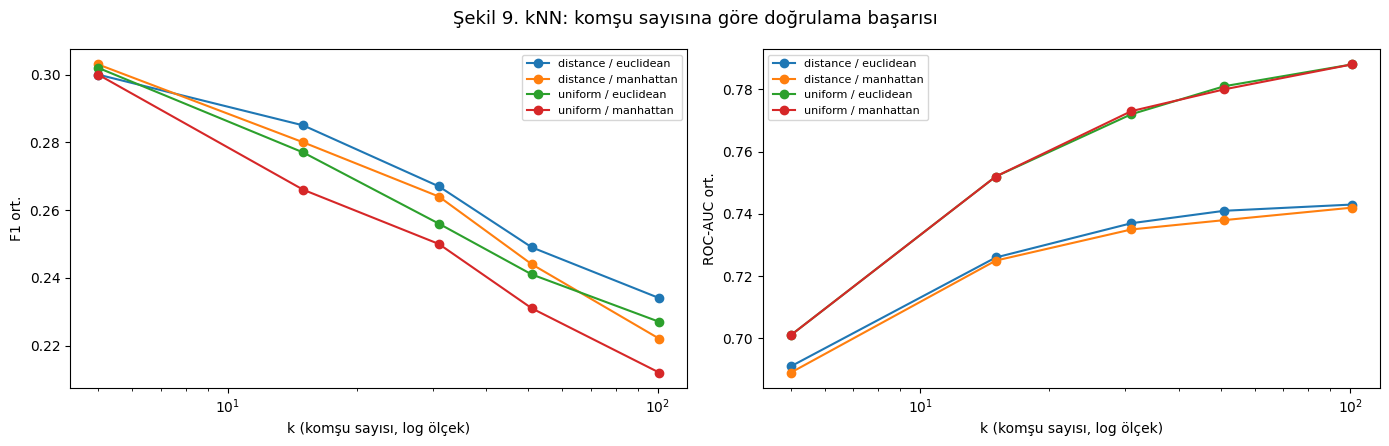

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, olcut in zip(axes, ['F1 ort.', 'ROC-AUC ort.']):
    for (agirlik, mesafe), g in tablo12.groupby(['ağırlık', 'mesafe']):
        g = g.sort_values('k')
        ax.plot(g['k'], g[olcut], marker='o', label=f'{agirlik} / {mesafe}')
    ax.set_xscale('log')
    ax.set_xlabel('k (komşu sayısı, log ölçek)')
    ax.set_ylabel(olcut)
    ax.legend(fontsize=8)
fig.suptitle('Şekil 9. kNN: komşu sayısına göre doğrulama başarısı', fontsize=13)
plt.tight_layout()
plt.show()

In [10]:
lr_hat = Pipeline([('on', on_isleme()), ('secim', RFE20),
                   ('model', LogisticRegression(max_iter=2000, class_weight='balanced'))])
t0 = time.time()
lr_ara = GridSearchCV(lr_hat, {'model__C': [0.001, 0.01, 0.1, 1, 10]}, cv=cv,
                      scoring={'f1': 'f1', 'roc_auc': 'roc_auc'}, refit='f1', n_jobs=-1)
lr_ara.fit(X_egitim, y_egitim)
print(f'Süre: {time.time() - t0:.0f} sn')
print('En iyi C:', lr_ara.best_params_, f'| CV F1 = {lr_ara.best_score_:.3f}')
tablo13 = pd.DataFrame(lr_ara.cv_results_)[['param_model__C', 'mean_test_f1', 'std_test_f1', 'mean_test_roc_auc']].round(4)
tablo13.columns = ['C', 'F1 ort.', 'F1 ss', 'ROC-AUC ort.']
print('\nTablo 13. Lojistik regresyon – C ayarı (RFE-20, tüm eğitim kümesi, 5 katlı CV)')
display(tablo13)

Süre: 550 sn
En iyi C: {'model__C': 0.01} | CV F1 = 0.450

Tablo 13. Lojistik regresyon – C ayarı (RFE-20, tüm eğitim kümesi, 5 katlı CV)


,C,F1 ort.,F1 ss,ROC-AUC ort.
0,0.001,0.4487,0.0009,0.8019
1,0.010,0.4499,0.0012,0.8028
2,0.100,0.4499,0.0010,0.8028
3,1.000,0.4498,0.0010,0.8028
4,10.000,0.4498,0.0010,0.8028


**Yorum (Tablo 12, Şekil 9):** F1 ve ROC-AUC k'ya göre ters yönde değişmektedir: F1 k = 5'te en yüksektir (0,303) ancak bu ayarın ROC-AUC değeri en düşüktür (0,689); k = 101'de (eşit ağırlık) ROC-AUC en yüksektir (0,788), F1 ise düşüktür (0,227). Bunun nedeni F1'in sabit 0,5 karar eşiğinde hesaplanmasıdır: k büyüdükçe tahmin olasılıkları yumuşar ve sıkıntılıların %14 olduğu veride komşuların yarısından fazlasının sıkıntılı olması nadirleşir; model neredeyse kimseyi pozitif sınıflandırmaz. Küçük k ise gürültüye duyarlıdır (yüksek varyans, aşırı öğrenme) ve kişileri riske göre sıralamada en başarısız ayardır. Mesafe ağırlıklı oylama ROC-AUC'yi düşürmüştür; Öklid ve Manhattan mesafeleri benzer sonuç vermiştir. Bu nedenle k, eşikten bağımsız ROC-AUC ölçütüyle seçilmiş ve karar eşiği ayrıca belirlenmiştir (bkz. 5.1). k = 101 ızgaranın sınırında olduğundan arama daha büyük k değerleriyle genişletilmiştir.

**Yorum (Tablo 13):** C ≥ 0,01 için lojistik regresyonun başarısı değişmemektedir (F1 0,450, ROC-AUC 0,803); çok büyük örneklem ve 20 öznitelikle aşırı öğrenme riski düşük olduğundan düzenlileştirme etkisizdir. C = 0,01 seçilmiştir.

### 5.1 kNN için k'nın ROC-AUC ile seçimi ve karar eşiğinin belirlenmesi
kNN için k, eşit ağırlık ve Öklid mesafesiyle daha büyük değerlerde (101-301) ROC-AUC ölçütüyle aranmıştır. Ardından her iki model için karar eşiği belirlenmiştir: eğitim kümesinde çapraz doğrulama dışı (out-of-fold) tahmin olasılıkları elde edilmiş ve F1'i en yüksek yapan eşik seçilmiştir. Eşik yalnızca eğitim verisinden öğrenildiği için test kümesine bilgi sızmaz. Varsayılan 0,5 eşiği, sınıfların dengesiz olduğu durumda genellikle uygun değildir.

In [11]:
t0 = time.time()
k_ara = GridSearchCV(knn_hat, {'model__n_neighbors': [101, 151, 201, 301],
                               'model__weights': ['uniform'], 'model__metric': ['euclidean']},
                     cv=cv, scoring='roc_auc', n_jobs=-1).fit(X_alt, y_alt)
print(f'Süre: {time.time() - t0:.0f} sn')
k_sonuc = pd.DataFrame(k_ara.cv_results_)[['param_model__n_neighbors', 'mean_test_score', 'std_test_score']].round(4)
k_sonuc.columns = ['k', 'ROC-AUC ort.', 'ROC-AUC ss']
display(k_sonuc)
EN_IYI_K = k_ara.best_params_['model__n_neighbors']
print('ROC-AUC ile seçilen k:', EN_IYI_K)

Süre: 109 sn


,k,ROC-AUC ort.,ROC-AUC ss
0,101,0.7884,0.0134
1,151,0.7897,0.0145
2,201,0.7915,0.0148
3,301,0.7926,0.0153


ROC-AUC ile seçilen k: 301


**Yorum.** k 101'den 301'e çıktıkça ROC-AUC 0,788'den 0,793'e yükseliyor. Artış sürekli ama çok küçük; katlar arası standart sapmanın (≈0,015) altında kalıyor. En yüksek değer ızgaranın kenarında (k = 301) çıktı. Daha büyük k değerleri denenmedi; kazanç çok küçük olduğu için k = 301 seçildi. Büyük k, her tahminin daha çok komşunun ortalamasına dayanması anlamına gelir. Bu da gürültülü ve sınıfları dengesiz bu veride olasılık tahminlerini daha kararlı hâle getirir.

In [12]:
from sklearn.base import clone
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import precision_recall_curve, f1_score

def esik_bul(hat, X, y):
    """Eğitim kümesinde out-of-fold olasılıklarla F1'i en yüksek yapan eşiği bulur."""
    p = cross_val_predict(hat, X, y, cv=cv, method='predict_proba', n_jobs=-1)[:, 1]
    kesinlik, duyarlilik, esikler = precision_recall_curve(y, p)
    f1 = 2 * kesinlik * duyarlilik / (kesinlik + duyarlilik + 1e-12)
    i = np.argmax(f1[:-1])
    return esikler[i], f1[i], f1_score(y, p >= 0.5)

LR_SON = Pipeline([('on', on_isleme()), ('secim', clone(RFE20)),
                   ('model', LogisticRegression(max_iter=2000, class_weight='balanced', C=0.01))])
KNN_SON = Pipeline([('on', on_isleme()), ('secim', clone(RFE20)),
                    ('model', KNeighborsClassifier(n_neighbors=EN_IYI_K, weights='uniform',
                                                   metric='euclidean', n_jobs=1))])

t0 = time.time()
lr_esik, lr_f1_esik, lr_f1_05 = esik_bul(LR_SON, X_egitim, y_egitim)
knn_esik, knn_f1_esik, knn_f1_05 = esik_bul(KNN_SON, X_alt, y_alt)
print(f'Süre: {time.time() - t0:.0f} sn')

tablo14 = pd.DataFrame({
    'eğitim verisi': ['tam (279.739)', 'alt örneklem (40.000)'],
    'F1 (eşik 0,5)': [lr_f1_05, knn_f1_05],
    'seçilen eşik': [lr_esik, knn_esik],
    'F1 (seçilen eşik)': [lr_f1_esik, knn_f1_esik],
}, index=['Lojistik regresyon (C = 0,01)', f'kNN (k = {EN_IYI_K})']).round(3)
print('Tablo 14. Karar eşiğinin belirlenmesi (eğitim kümesi, out-of-fold tahminler)')
display(tablo14)

Süre: 127 sn
Tablo 14. Karar eşiğinin belirlenmesi (eğitim kümesi, out-of-fold tahminler)


,eğitim verisi,"F1 (eşik 0,5)",seçilen eşik,F1 (seçilen eşik)
"Lojistik regresyon (C = 0,01)",tam (279.739),0.450,0.625,0.470
kNN (k = 301),alt örneklem (40.000),0.196,0.193,0.462


**Yorum.** Karar eşiği yalnızca eğitim kümesinde, modelin görmediği katlardan elde edilen (out-of-fold) tahminlerle belirlendi; test kümesi kullanılmadı.
- **kNN:** 0,5 eşiğinde F1 = 0,196 iken, eşik 0,193'e indirildiğinde F1 = 0,462'ye çıktı. kNN'nin Tablo 9-12'de zayıf görünmesinin ana nedeni modelin kendisi değil, 0,5 eşiğiymiş. Pozitif oran %14 olduğu için 301 komşunun yarısından fazlasının "sıkıntılı" olması nadiren gerçekleşir. Bu yüzden F1'i en büyük yapan eşik 0,5'in çok altında çıktı.
- **Lojistik regresyon:** Eşik 0,625'e çıktığında F1 0,450'den 0,470'e yükseldi. `class_weight='balanced'` pozitif sınıfa fazla ağırlık vererek olasılıkları yukarı kaydırmış; eşiğin 0,5'in üstüne çıkması kesinliği artırarak bunu dengeliyor.
- **Sonuç:** Eşik ayarından sonra iki modelin F1 değerleri birbirine yakın (0,470 ve 0,462). Hangisinin tercih edileceği test sonucunda (Bölüm 6) değerlendirilecek.

## 6. Test kümesinde değerlendirme

Bu bölüme kadar alınan tüm kararlar yalnızca eğitim kümesiyle verildi: öznitelik seçimi (RFE-20), hiperparametreler (LR için C = 0,01, kNN için k = 301) ve karar eşikleri (0,625 ve 0,193). Şimdi modeller son kez eğitilip, en başta ayrılan ve hiç dokunulmamış test kümesinde (69.935 kişi) **tek seferlik** değerlendiriliyor. Karşılaştırma için her zaman çoğunluk sınıfını tahmin eden basit model (Dummy) ve 0,5 eşiğindeki sonuçlar da tabloda yer alıyor.

In [13]:
import time
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (f1_score, roc_auc_score, recall_score,
                             precision_score, accuracy_score)

t0 = time.time()
# 1) Son modelleri eğit (LR tam eğitim kümesiyle, kNN 40k alt örneklemle)
LR_SON.fit(X_egitim, y_egitim)
KNN_SON.fit(X_alt, y_alt)
dummy = DummyClassifier(strategy='most_frequent').fit(X_egitim, y_egitim)

# 2) Test kümesi için olasılıklar
p_lr    = LR_SON.predict_proba(X_test)[:, 1]
p_knn   = KNN_SON.predict_proba(X_test)[:, 1]
p_dummy = dummy.predict_proba(X_test)[:, 1]

# 3) Her satır: (ad, olasılıklar, eşik)
satirlar = [('Dummy (çoğunluk sınıfı)',  p_dummy, 0.5),
            ('Lojistik regresyon',       p_lr,    0.5),
            ('Lojistik regresyon',       p_lr,    lr_esik),
            ('kNN (k = 301)',            p_knn,   0.5),
            ('kNN (k = 301)',            p_knn,   knn_esik)]

sonuc = []
for ad, p, esik in satirlar:
    tahmin = (p >= esik).astype(int)
    sonuc.append({'model': ad, 'eşik': round(esik, 3),
                  'F1': f1_score(y_test, tahmin),
                  'ROC-AUC': roc_auc_score(y_test, p),
                  'duyarlılık': recall_score(y_test, tahmin),
                  'kesinlik': precision_score(y_test, tahmin, zero_division=0),
                  'doğruluk': accuracy_score(y_test, tahmin)})

tablo15 = pd.DataFrame(sonuc).round(3)
tablo15.to_csv(klasor + '/tablo15_test_sonuclari.csv', index=False)
print(f'Süre: {time.time()-t0:.0f} sn')
print('Tablo 15. Test kümesi sonuçları (n = 69.935, pozitif oran %14,4)')
tablo15

Süre: 101 sn
Tablo 15. Test kümesi sonuçları (n = 69.935, pozitif oran %14,4)


,model,eşik,F1,ROC-AUC,duyarlılık,kesinlik,doğruluk
0,Dummy (çoğunluk sınıfı),0.500,0.000,0.500,0.000,0.000,0.856
1,Lojistik regresyon,0.500,0.448,0.800,0.688,0.332,0.757
2,Lojistik regresyon,0.625,0.464,0.800,0.540,0.408,0.821
3,kNN (k = 301),0.500,0.181,0.793,0.104,0.679,0.864
4,kNN (k = 301),0.193,0.459,0.793,0.533,0.403,0.820


In [14]:
# Kontrol: iki modelin RFE seçimleri birbirinden bağımsız mı ve aynı mı?
ad_lr  = set(LR_SON.named_steps['on'].get_feature_names_out()[LR_SON.named_steps['secim'].get_support()])
ad_knn = set(KNN_SON.named_steps['on'].get_feature_names_out()[KNN_SON.named_steps['secim'].get_support()])
print('Ayrı RFE nesneleri:', LR_SON.named_steps['secim'] is not KNN_SON.named_steps['secim'])
print('Tüm eğitim (LR) ve alt örneklem (kNN) RFE seçimleri aynı mı:', ad_lr == ad_knn)
print('Yalnız LR\'de:', sorted(ad_lr - ad_knn))
print('Yalnız kNN\'de:', sorted(ad_knn - ad_lr))

Ayrı RFE nesneleri: True
Tüm eğitim (LR) ve alt örneklem (kNN) RFE seçimleri aynı mı: False
Yalnız LR'de: ['ikili__BLIND', 'ikili__VETERAN3', 'nominal___RACEGR3_1.0', 'nominal___RACEGR3_4.0']
Yalnız kNN'de: ['ikili__DEAF', 'ikili___HLTHPL2', 'nominal___RACEGR3_3.0', 'nominal___RACEGR3_5.0']


**Yorum.** Test sonuçları, eğitim kümesindeki çapraz doğrulama değerleriyle uyumlu: LR'de F1 0,470'ten 0,464'e, ROC-AUC 0,803'ten 0,800'e çok az düştü; kNN'de F1 0,462'den 0,459'a indi, AUC aynı kaldı. Bu küçük farklar, belirgin bir aşırı öğrenme olmadığını gösteriyor. (Test kümesi aynı anketten ayrıldığı için bu, başka yıllara ya da nüfuslara genellenebilirliği göstermez.)

* **RFE kontrolü:** Son iki model artık ayrı RFE nesneleri kullanıyor (`clone(RFE20)`). Önceki sürümde ikisi aynı nesneyi paylaşıyordu; kNN alt örneklemle eğitilirken LR'nin seçtiği sütunların üzerine yazılıyordu. Kontrol hücresi, tüm eğitim kümesinde (LR) ve 40.000 kişilik alt örneklemde (kNN) RFE'nin seçtiği 20 sütunun 16'sının ortak, 4'ünün farklı olduğunu gösteriyor. LR'nin sonuçları artık kendi seçtiği sütunlarla hesaplanıyor.
* **Doğruluk tuzağı:** Dummy model hiç kimseyi "sıkıntılı" olarak işaretlemeden %85,6 doğruluk elde ediyor. 0,5 eşiğindeki kNN ise %86,4 doğrulukla tablonun en "doğru" modeli görünüyor, ama sıkıntılı kişilerin yalnızca %10'unu yakalıyor. Bu nedenle doğruluk bu problemde yanıltıcı; F1 ve ROC-AUC esas alındı.
* **Eşik ayarının etkisi:** Eğitimde seçilen eşikler testte de işe yaradı: LR'de F1 0,448'den 0,464'e, kNN'de 0,181'den 0,459'a yükseldi. (kNN'de çok sayıda kişi birbirine eşit uzaklıkta olduğundan, eşitliklerin çözümü nedeniyle sonuçlar çalıştırmalar arasında üçüncü ondalıkta değişebilmektedir.)
* **İki model aynı tavanda:** Yalnızca 40.000 kişiyle eğitilen kNN ile 279.739 kişiyle eğitilen LR neredeyse aynı sonucu verdi (F1 ≈ 0,46; ROC-AUC 0,79–0,80). Birbirinden çok farklı çalışan iki algoritmanın aynı noktada durması, sınırın algoritmada ya da veri miktarında değil, özniteliklerin taşıdığı bilgide olduğunu düşündürüyor.
* **Tercih edilen model: lojistik regresyon.** Başarısı kNN ile aynı düzeyde. Bunun yanında tüm eğitim verisini kullanıyor, saniyeler içinde eğitilip tahmin yapıyor (kNN her yeni kişi için 40.000 kişiyle mesafe hesaplamak zorunda) ve katsayıları yorumlanabiliyor (Tablo 16).

### 6.1 Karmaşıklık matrisleri ve ROC eğrileri
Karmaşıklık matrisi, modelin kimleri doğru yakaladığını (doğru pozitif), kimleri kaçırdığını (yanlış negatif) ve kimleri gereksiz yere işaretlediğini (yanlış pozitif) sayı olarak gösterir. ROC eğrisi ise eşikten bağımsız olarak modelin sıralama başarısını gösterir. Eğrinin üzerindeki nokta, seçilen eşikte modelin bulunduğu yeri işaretler.

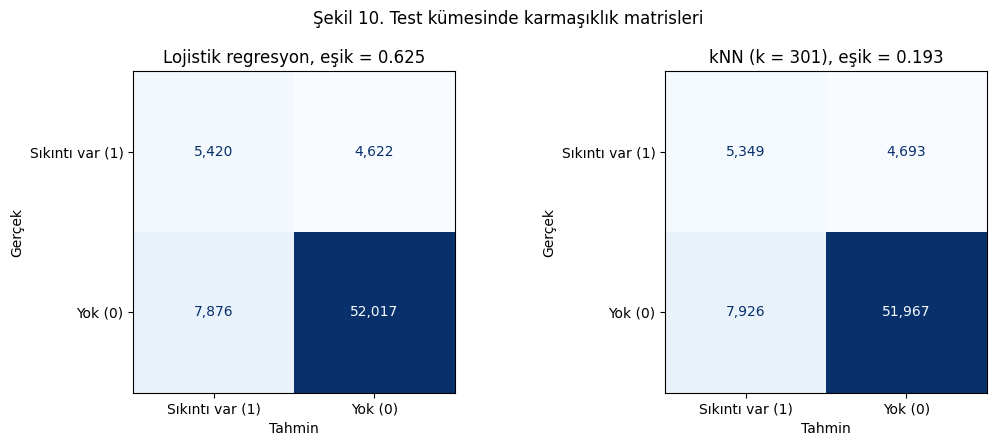

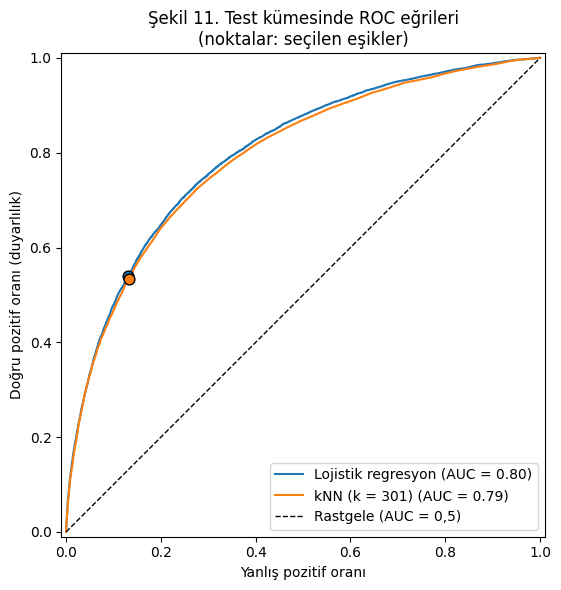

In [15]:
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay

# Şekil 10: karmaşıklık matrisleri (seçilen eşiklerde)
fig, eksen = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, (ad, p, esik) in zip(eksen, [('Lojistik regresyon', p_lr, lr_esik),
                                      ('kNN (k = 301)', p_knn, knn_esik)]):
    ConfusionMatrixDisplay.from_predictions(
        y_test, (p >= esik).astype(int), labels=[1, 0],
        display_labels=['Sıkıntı var (1)', 'Yok (0)'],
        values_format=',d', colorbar=False, cmap='Blues', ax=ax)
    ax.set_title(f'{ad}, eşik = {esik:.3f}')
    ax.set_xlabel('Tahmin'); ax.set_ylabel('Gerçek')
plt.suptitle('Şekil 10. Test kümesinde karmaşıklık matrisleri')
plt.tight_layout(); plt.show()

# Şekil 11: ROC eğrileri + seçilen eşik noktaları
fig, ax = plt.subplots(figsize=(6, 6))
for ad, p, esik, renk in [('Lojistik regresyon', p_lr, lr_esik, 'C0'),
                          ('kNN (k = 301)', p_knn, knn_esik, 'C1')]:
    RocCurveDisplay.from_predictions(y_test, p, name=ad, color=renk, ax=ax)
    tahmin = p >= esik
    tpr = tahmin[y_test == 1].mean()          # duyarlılık
    fpr = tahmin[y_test == 0].mean()          # yanlış alarm oranı
    ax.scatter(fpr, tpr, color=renk, s=60, zorder=3, edgecolor='black')
ax.plot([0, 1], [0, 1], 'k--', lw=1, label='Rastgele (AUC = 0,5)')
ax.set_xlabel('Yanlış pozitif oranı'); ax.set_ylabel('Doğru pozitif oranı (duyarlılık)')
ax.set_title('Şekil 11. Test kümesinde ROC eğrileri\n(noktalar: seçilen eşikler)')
ax.legend(loc='lower right'); plt.tight_layout(); plt.show()

**Yorum.** Test kümesinde 10.042 sıkıntılı kişi var. Lojistik regresyon bunların 5.420'sini doğru yakalıyor (duyarlılık %54,0), 4.622'sini kaçırıyor; buna karşılık 7.876 kişiyi gereksiz yere işaretliyor. Model toplamda kişilerin %19,0'unu işaretliyor ve işaretlediklerinin %40,8'i gerçekten sıkıntılı. Bu oran rastgele seçime göre (%14,4) yaklaşık 2,8 kat daha yüksek.

İki modelin işaretlediği kişi sayısı neredeyse aynı (LR 13.296, kNN 13.275); LR bunlar arasında biraz daha fazla gerçek pozitif yakalıyor (5.420'ye karşı 5.349). Şekil 11'de iki ROC eğrisi neredeyse üst üste; seçilen eşikler eğrinin aynı bölgesinde duruyor.

Bir tarama aracı olarak düşünüldüğünde bu model tek başına karar vermek için değil, kimlerle daha ayrıntılı görüşme yapılması gerektiğini önceliklendirmek için uygun. Kaçırılan kişilerin bedeli yüksekse eşik düşürülerek duyarlılık artırılabilir; bunun karşılığı daha fazla yanlış alarmdır.

### 6.2 Modelin yorumlanması: lojistik regresyon katsayıları
Lojistik regresyonun avantajı, her özniteliğin etkisinin okunabilmesidir. Olasılık oranı (OR) 1'den büyükse öznitelik sık ruhsal sıkıntı olasılığını artırıyor, 1'den küçükse azaltıyor demektir. Sayısal ve sıralı değişkenler standartlaştırıldığı için onlarda OR "1 standart sapma artış" için, ikili ve kategorik değişkenlerde ise "0'dan 1'e geçiş" için yorumlanır. Bunlar nedensel değil, diğer değişkenler sabitken gözlenen ilişkilerdir.

In [16]:
on   = LR_SON.named_steps['on']
rfe  = LR_SON.named_steps['secim']
lr   = LR_SON.named_steps['model']

adlar = on.get_feature_names_out()[rfe.get_support()]
tablo16 = pd.DataFrame({
    'grup':      [a.split('__', 1)[0] for a in adlar],
    'öznitelik': [a.split('__', 1)[1] for a in adlar],
    'katsayı':   lr.coef_[0],
    'OR':        np.exp(lr.coef_[0])})
tablo16 = tablo16.sort_values('katsayı', key=abs, ascending=False).round(3).reset_index(drop=True)
tablo16.to_csv(klasor + '/tablo16_lr_katsayilar.csv', index=False)
print('Tablo 16. Lojistik regresyon (RFE-20, C = 0,01) katsayıları, etki büyüklüğüne göre')
tablo16

Tablo 16. Lojistik regresyon (RFE-20, C = 0,01) katsayıları, etki büyüklüğüne göre


,grup,öznitelik,katsayı,OR
0,ikili,MEDCOST1,0.732,2.079
1,ikili,_CURECI3,0.517,1.677
2,sayisal,_AGE80,-0.515,0.598
3,ikili,SEXVAR,0.482,1.620
4,sirali,GENHLTH,0.453,1.574
5,nominal,EMPLOY1_8.0,0.453,1.573
6,nominal,EMPLOY1_4.0,0.444,1.559
7,ikili,_RFDRHV9,0.434,1.543
8,sayisal,PHYSHLTH,0.424,1.528
9,nominal,_RACEGR3_4.0,0.371,1.449


**Yorum.** OR > 1 olan öznitelikler sık ruhsal sıkıntının daha yüksek, OR < 1 olanlar daha düşük olasılığıyla ilişkili.

* **En güçlü ilişki:** Maliyet nedeniyle doktora gidememek (MEDCOST1). Diğer değişkenler sabitken sık ruhsal sıkıntının odds'u yaklaşık iki katına çıkıyor (OR = 2,08).
* **Daha yüksek riskle ilişkili olanlar:** Güncel e-sigara kullanımı (1,68), kadın olmak (1,62), ağır alkol tüketimi (1,54), çalışamaz durumda (1,57) ya da işsiz olmak (1,43–1,56), kötü genel sağlık (1,57), fiziksel sağlığın kötü olduğu gün sayısı (1,53), uykunun 7–8 saatten sapması (1,31), görme güçlüğü (1,29) ve giyinme/yıkanma güçlüğü (1,23).
* **Daha düşük riskle ilişkili olanlar:** Yaş (1 standart sapma artış başına 0,60) ve evli olmak (0,75). Bu sonuçlar Notebook 1, Bölüm 6.3 bulgularıyla tutarlı.
* **Tek değişkenli bulgudan farklı görünen:** Gazilik (VETERAN3) tek değişkenli analizde hedefle neredeyse ilişkisizdi (Cramér's V = 0,006), modelde ise OR = 1,36 ile daha yüksek riskle ilişkili çıkıyor. Bu, modeldeki diğer değişkenler sabit tutulduğunda ortaya çıkan koşullu bir ilişkidir; tek değişkenli bulguyla doğrudan çelişmez. Ancak gazilik yalnızca LR'nin RFE seçiminde yer alıyor ve permütasyon önemi küçük (0,0024); bu yüzden temkinle yorumlanmalı. Nedeni Faz 2'de incelenecek.
* **Irk/etnisite:** Seçilen iki kategori (Hispanik olmayan çok ırklı 1,45; Hispanik olmayan beyaz 1,35) seçilmeyen kategorilere göre yorumlanmalıdır.
* **Diyabet:** "Diyabet var" (0,79) ve "diyabet yok" (0,83) katsayıları neredeyse aynı. Yani diyabetin kendisi ayırt edici değil; ikisi de karşılaştırma kategorisi olan prediyabete göre biraz düşük.

**Dikkat edilecek noktalar.**

1. Bu veri kesitsel olduğu için ilişkiler nedensel değildir; ters yön de mümkündür (ör. ruhsal sıkıntı e-sigara kullanımını artırıyor olabilir).
2. Kategorik değişkenlerde bir referans kategori düşürülmediği ve yalnızca bazı kategoriler seçildiği için bu katsayılar seçilmeyen kategorilere göre yorumlanmalıdır.

**Eyleme dönük içgörüler.** Değiştirilebilir olabilecek ilişkili etkenler arasında maliyet nedeniyle sağlık hizmetine erişememe, işsizlik, uyku süresi ile e-sigara ve ağır alkol kullanımı öne çıkıyor. Ruh sağlığı taramalarında bu sorulara verilen yanıtlar, kimlere öncelik verileceğini belirlemek için kullanılabilir.

### 6.3 Kesinlik-duyarlılık eğrisi ve PR-AUC
Sınıfların dengesiz olduğu verilerde ROC-AUC iyimser bir tablo çizebilir: büyük "sıkıntı yok" sınıfındaki doğru sınıflamalar yanlış pozitif oranını küçük gösterir ve nadir sınıftaki zayıflığı gizler. Kesinlik-duyarlılık (precision-recall) eğrisi ise yalnızca pozitif sınıfa odaklanır: model sıkıntılı kişileri yakaladıkça işaretlediklerinin ne kadarının gerçekten sıkıntılı olduğunu gösterir. Eğrinin altındaki alan (PR-AUC, ortalama kesinlik / average precision) için rastgele modelin değeri pozitif sınıfın oranına (taban oran, ≈ 0,144) eşittir; ROC-AUC'deki 0,5'in karşılığı budur.

Tablo 17. Test kümesinde PR-AUC ve ROC-AUC (taban oran = 0.144)


,model,PR-AUC (ortalama kesinlik),ROC-AUC
0,Dummy (çoğunluk sınıfı),0.144,0.500
1,Lojistik regresyon,0.443,0.800
2,kNN (k = 301),0.434,0.793


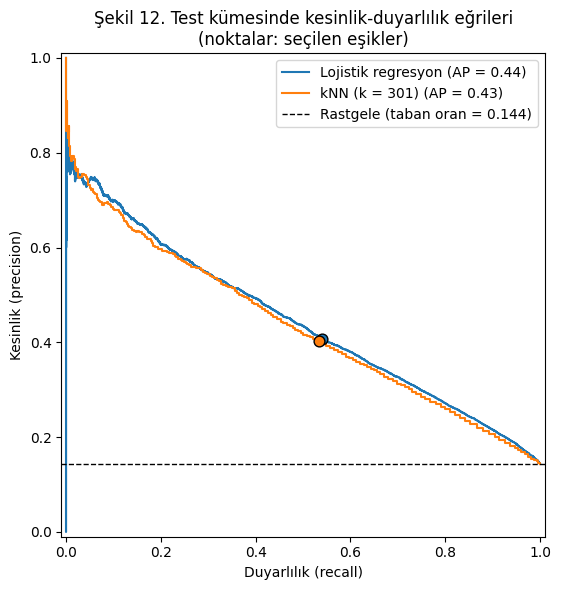

In [17]:
from sklearn.metrics import average_precision_score, PrecisionRecallDisplay

taban = y_test.mean()
olasiliklar = [('Dummy (çoğunluk sınıfı)', p_dummy), ('Lojistik regresyon', p_lr), (f'kNN (k = {EN_IYI_K})', p_knn)]
tablo17 = pd.DataFrame({
    'model': [ad for ad, p in olasiliklar],
    'PR-AUC (ortalama kesinlik)': [average_precision_score(y_test, p) for ad, p in olasiliklar],
    'ROC-AUC': [roc_auc_score(y_test, p) for ad, p in olasiliklar],
}).round(3)
tablo17.to_csv(klasor + '/tablo17_pr_auc.csv', index=False)
print(f'Tablo 17. Test kümesinde PR-AUC ve ROC-AUC (taban oran = {taban:.3f})')
display(tablo17)

# Şekil 12: kesinlik-duyarlılık eğrileri + seçilen eşik noktaları
fig, ax = plt.subplots(figsize=(6, 6))
for ad, p, esik, renk in [('Lojistik regresyon', p_lr, lr_esik, 'C0'),
                          (f'kNN (k = {EN_IYI_K})', p_knn, knn_esik, 'C1')]:
    PrecisionRecallDisplay.from_predictions(y_test, p, name=ad, color=renk, ax=ax)
    tahmin = p >= esik
    ax.scatter(tahmin[y_test == 1].mean(), y_test[tahmin].mean(),   # (duyarlılık, kesinlik)
               color=renk, s=60, zorder=3, edgecolor='black')
ax.axhline(taban, color='k', ls='--', lw=1, label=f'Rastgele (taban oran = {taban:.3f})')
ax.set_xlabel('Duyarlılık (recall)'); ax.set_ylabel('Kesinlik (precision)')
ax.set_title('Şekil 12. Test kümesinde kesinlik-duyarlılık eğrileri\n(noktalar: seçilen eşikler)')
ax.legend(loc='upper right'); plt.tight_layout(); plt.show()

**Yorum (Tablo 17, Şekil 12):** PR-AUC, ROC-AUC'ye göre çok daha temkinli bir tablo çiziyor: ROC-AUC 0,79–0,80 iken PR-AUC lojistik regresyonda 0,443, kNN'de 0,434. Rastgele bir modelin PR-AUC değeri taban orana (0,144) eşit olduğundan iki model de rastgele modelin yaklaşık 3 katı başarı gösteriyor. Buna karşın PR-AUC'nin 0,5'in altında kalması, nadir sınıfı yüksek kesinlikle yakalamanın bu özniteliklerle zor olduğunu gösteriyor.

Şekil 12'de duyarlılık arttıkça kesinlik düzenli olarak düşüyor. Seçilen eşiklerde lojistik regresyon sıkıntılı kişilerin %54,0'ını %40,8 kesinlikle, kNN %53,3'ünü %40,3 kesinlikle yakalıyor. İki modelin eğrileri ve PR-AUC değerleri birbirine çok yakın; bu, Bölüm 6'daki "aynı tavan" bulgusunu dengesiz veriye daha uygun bir ölçütle doğruluyor.

### 6.4 Permütasyon önemi (lojistik regresyon)
Katsayılar (Tablo 16) yalnızca RFE'nin seçtiği 20 sütunu ve tek-sıcak kodlanmış kategorileri ayrı ayrı gösterir. Permütasyon önemi ise her **ham** özniteliğin (43 öznitelik) model başarısına katkısını tek bir sayıyla ölçer: test kümesinde bir özniteliğin değerleri rastgele karıştırılır ve PR-AUC'nin ne kadar düştüğüne bakılır. Büyük düşüş, modelin o özniteliğe çok dayandığını gösterir. İşlem 10 kez tekrarlanmış, ortalama ve standart sapma raporlanmıştır. Model zaten eğitilmiş olduğundan bu analiz hiçbir model kararını değiştirmez; yalnızca yorumlama amaçlıdır. RFE'nin seçmediği özniteliklerin önemi tanım gereği sıfırdır.

Süre: 66 sn
Tablo 18. Lojistik regresyon – permütasyon önemi (test kümesi, PR-AUC düşüşü, 10 tekrar), ilk 15


,öznitelik,önem (PR-AUC düşüşü),ss
0,PHYSHLTH,0.0721,0.0019
1,_AGE80,0.0635,0.0019
2,GENHLTH,0.0585,0.0012
3,UYKU_SAPMA,0.0191,0.0007
4,MEDCOST1,0.0191,0.0006
5,SEXVAR,0.0107,0.0007
6,_CURECI3,0.0075,0.0004
7,EMPLOY1,0.0065,0.0006
8,_RACEGR3,0.0061,0.0006
9,MARITAL,0.0041,0.0007


Önemi sıfır olan (modelin kullanmadığı) öznitelik sayısı: 27


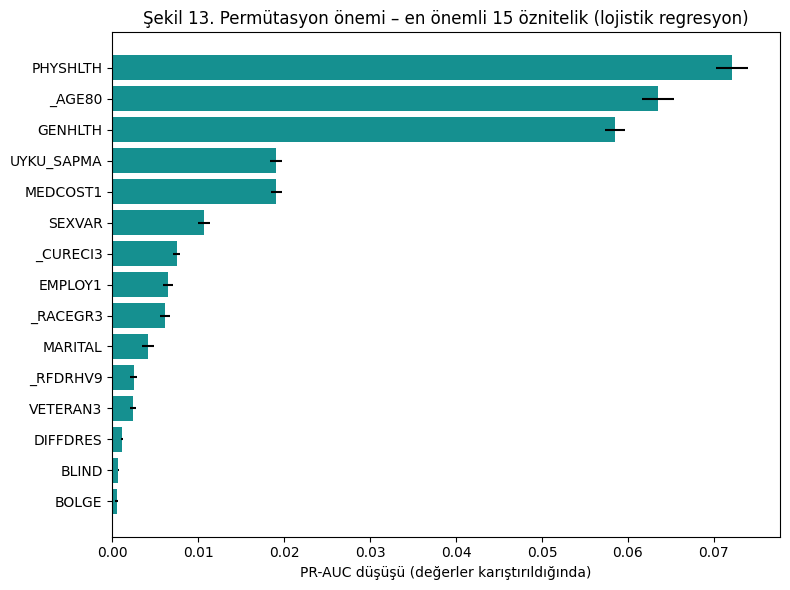

In [18]:
from sklearn.inspection import permutation_importance

t0 = time.time()
pi = permutation_importance(LR_SON, X_test, y_test, scoring='average_precision',
                            n_repeats=10, random_state=RANDOM_STATE, n_jobs=-1)
print(f'Süre: {time.time() - t0:.0f} sn')

tablo18 = pd.DataFrame({'öznitelik': X_test.columns,
                        'önem (PR-AUC düşüşü)': pi.importances_mean,
                        'ss': pi.importances_std})
tablo18 = tablo18.sort_values('önem (PR-AUC düşüşü)', ascending=False).round(4).reset_index(drop=True)
tablo18.to_csv(klasor + '/tablo18_permutasyon_onemi.csv', index=False)
print('Tablo 18. Lojistik regresyon – permütasyon önemi (test kümesi, PR-AUC düşüşü, 10 tekrar), ilk 15')
display(tablo18.head(15))
print('Önemi sıfır olan (modelin kullanmadığı) öznitelik sayısı:', (tablo18['önem (PR-AUC düşüşü)'].abs() < 1e-4).sum())

# Şekil 13: en önemli 15 öznitelik
ilk = tablo18.head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(ilk['öznitelik'], ilk['önem (PR-AUC düşüşü)'], xerr=ilk['ss'], color='#159090')
ax.set_xlabel('PR-AUC düşüşü (değerler karıştırıldığında)')
ax.set_title('Şekil 13. Permütasyon önemi – en önemli 15 öznitelik (lojistik regresyon)')
plt.tight_layout(); plt.show()

**Yorum (Tablo 18, Şekil 13):** Model başarısının büyük kısmı üç öznitelikten geliyor: fiziksel sağlığın kötü olduğu gün sayısı (PR-AUC düşüşü 0,072), yaş (0,064) ve genel sağlık (0,059). Bunları ideal uykudan sapma ve maliyet nedeniyle doktora gidememe (ikisi de 0,019) izliyor. Öznitelik mühendisliğiyle üretilen uykudan sapma değişkeninin dördüncü sırada yer alması, bu dönüşümün modele gerçek bir katkı sağladığını gösteriyor. 43 özniteliğin 27'sinin önemi sıfır; model RFE'nin seçtiği 16 ham özniteliğe dayanıyor.

Permütasyon önemi ile katsayılar (Tablo 16) farklı sorulara yanıt veriyor. Maliyet nedeniyle doktora gidememe en büyük katsayıya sahip (OR = 2,08), ancak permütasyonda uykudan sapmayla paylaştığı dördüncü sırada. Bu değişken ikili ve yalnızca kişilerin yaklaşık %10'unda "evet" olduğundan modelin tahminlerine kattığı değişkenlik, herkeste farklı değer alan fiziksel sağlık, yaş ve genel sağlıktan küçük kalıyor. Katsayı, diğer değişkenler sabitken etkinin büyüklüğünü; permütasyon önemi ise o özniteliğin örneklem genelinde modelin başarısına katkısını ölçer. Sıralama Cramér's V (Notebook 1, Tablo 4) ve öznitelik seçimi yöntemlerinin ortak seçtikleriyle (Tablo 11) de tutarlı.

## 7. Özet, sınırlılıklar ve Faz 2 planı

**Özet.** BRFSS 2025 verisinde (eğitim 279.739, test 69.935 kişi), 43 öznitelikten (ön işleme sonrası 76 sütun) sık ruhsal sıkıntıyı tahmin eden iki model kuruldu. Öznitelik seçiminde RFE ile 20 sütun seçildi; hiperparametreler ve karar eşikleri yalnızca eğitim kümesinde çapraz doğrulamayla belirlendi. Test kümesinde lojistik regresyon F1 = 0,464, ROC-AUC = 0,800 ve PR-AUC = 0,443; kNN F1 = 0,459, ROC-AUC = 0,793 ve PR-AUC = 0,434 elde etti. İki model de Dummy modele (F1 = 0) göre belirgin biçimde daha iyi. Tercih edilen model lojistik regresyondur.

**Sınırlılıklar.**
- Anket ağırlıkları kullanılmadı. Örneklem, ABD nüfusuna göre daha yaşlı, daha eğitimli ve beyaz oranı daha yüksek; sonuçlar nüfusa genellenirken bu dikkate alınmalı.
- Veri kesitsel ve öz bildirime dayalı; ilişkiler nedensel değildir.
- kNN, hesaplama maliyeti nedeniyle 40.000 kişilik tabakalı bir alt örneklemle eğitildi.
- Hedef değişken tek bir soruya (son 30 günde ruh sağlığının kötü olduğu gün sayısı) dayanıyor; klinik bir tanı değildir.

**Faz 2 planı.**
- Dersin vize sonrası konularına göre ağaç tabanlı ve topluluk modelleri (karar ağacı, rastgele orman, gradyan artırma) eklenecek ve aynı protokolle karşılaştırılacak.
- Yorumlanabilirlik genişletilecek: ağaç tabanlı modellerde permütasyon önemi ile modelin kendi önem ölçüleri karşılaştırılacak.
- **Adillik:** Modelin performansı cinsiyet, yaş grubu ve ırk/etnisite alt gruplarında ayrı ayrı ölçülecek; modelin bazı gruplarda daha çok kişiyi kaçırıp kaçırmadığı kontrol edilecek.

## 8. Rapor şekilleri

Bu hücre yeni bir hesap yapmaz; yukarıdaki sonuçları IEEE rapor sütunu genişliğinde (8 pt yazı, ondalık virgül) yeniden çizer ve Drive'a kaydeder. Rapordaki Şekil 1 (dağılımlar), Şekil 3 (ROC ve kesinlik-duyarlılık eğrileri) ve Şekil 4 (permütasyon önemi) bu hücrenin çıktılarıdır.

Yaş (yıl; 80+ = 80): ortalama 55,7, medyan 59,0, çarpıklık -0,39
Hanedeki çocuk sayısı: ortalama 0,5, medyan 0,0, çarpıklık 13,25
Uyku (saat): ortalama 7,1, medyan 7,0, çarpıklık 0,89
Fiziksel sağlığın kötü olduğu gün: ortalama 4,7, medyan 0,0, çarpıklık 2,04
Beden kitle indeksi: ortalama 28,5, medyan 27,4, çarpıklık 1,42
Alkol alınan gün (son 30 gün): ortalama 4,2, medyan 0,0, çarpıklık 2,22


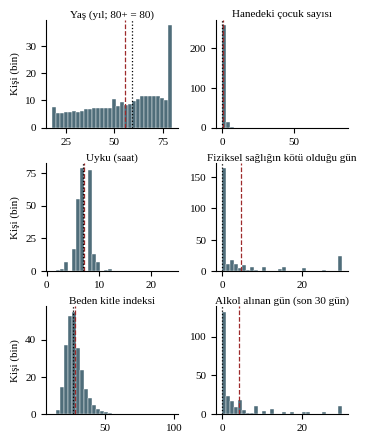

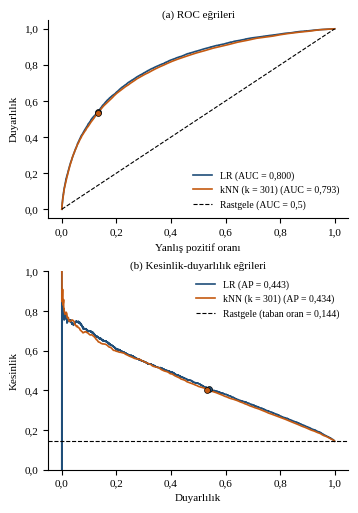

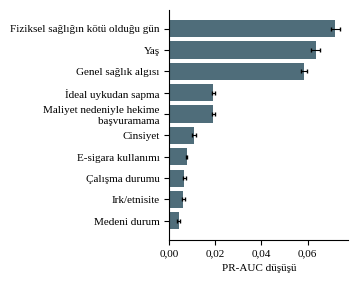

Kaydedildi: /content/drive/MyDrive/YL: Yapay Zeka/VeriMadenciligi/veri


In [19]:
# 8. Rapor şekilleri (IEEE sütun genişliği, 8 pt yazı, ondalık virgül)
# Bu hücre yeni hesap yapmaz; yukarıdaki sonuçları rapor boyutunda çizer ve Drive'a kaydeder.
!apt-get -qq install -y fonts-liberation > /dev/null 2>&1
import matplotlib as mpl, matplotlib.font_manager as fm
from matplotlib.ticker import FuncFormatter
from sklearn.metrics import roc_curve, precision_recall_curve, roc_auc_score, average_precision_score
for f in glob.glob('/usr/share/fonts/truetype/liberation/LiberationSerif-*.ttf'):
    fm.fontManager.addfont(f)
mpl.rcParams.update({'font.family': 'serif', 'font.serif': ['Liberation Serif', 'DejaVu Serif'],
                     'font.size': 8, 'axes.titlesize': 8, 'axes.labelsize': 8, 'xtick.labelsize': 8,
                     'ytick.labelsize': 8, 'legend.fontsize': 7, 'axes.spines.top': False,
                     'axes.spines.right': False})
virgul = lambda b: FuncFormatter(lambda x, _: f'{x:.{b}f}'.replace('.', ','))
v = lambda x, b: f'{x:.{b}f}'.replace('.', ',')

# Rapor Şekil 2: sayısal değişkenlerin dağılımı (eğitim kümesi, ham değerler)
DAG = [('_AGE80', 'Yaş (yıl; 80+ = 80)'), ('CHILDREN', 'Hanedeki çocuk sayısı'),
       ('SLEPTIM1', 'Uyku (saat)'), ('PHYSHLTH', 'Fiziksel sağlığın kötü olduğu gün'),
       ('_BMI5', 'Beden kitle indeksi'), ('ALKOL_GUN', 'Alkol alınan gün (son 30 gün)')]
fig, eksen = plt.subplots(3, 2, figsize=(3.45, 4.3))
for ax, (s, ad) in zip(eksen.ravel(), DAG):
    x = egitim[s].dropna()
    ax.hist(x, bins=30, color='#4F6D7A', edgecolor='white', linewidth=0.3)
    ax.axvline(x.mean(), color='#9E2A2B', ls='--', lw=0.9)
    ax.axvline(x.median(), color='black', ls=':', lw=0.9)
    ax.set_title(ad, pad=2)
    ax.yaxis.set_major_formatter(FuncFormatter(lambda y, _: f'{y/1000:.0f}'))
    print(f'{ad}: ortalama {v(x.mean(), 1)}, medyan {v(x.median(), 1)}, çarpıklık {v(x.skew(), 2)}')
for ax in eksen[:, 0]:
    ax.set_ylabel('Kişi (bin)')
plt.tight_layout(pad=0.3, h_pad=0.6, w_pad=0.6)
plt.savefig(klasor + '/rapor_sekil2_dagilim.png', dpi=400)
plt.show()

# Rapor Şekil 3: (a) ROC ve (b) kesinlik-duyarlılık eğrileri, seçilen eşikler nokta ile
taban = y_test.mean()
fig, (a1, a2) = plt.subplots(2, 1, figsize=(3.45, 5.0))
for ad, p, esik, renk in [('LR', p_lr, lr_esik, '#1F4E79'), (f'kNN (k = {EN_IYI_K})', p_knn, knn_esik, '#C55A11')]:
    fpr, tpr, _ = roc_curve(y_test, p)
    a1.plot(fpr, tpr, color=renk, lw=1.2, label=f'{ad} (AUC = {v(roc_auc_score(y_test, p), 3)})')
    k, d, _ = precision_recall_curve(y_test, p)
    a2.plot(d, k, color=renk, lw=1.2, label=f'{ad} (AP = {v(average_precision_score(y_test, p), 3)})')
    t = p >= esik
    a1.scatter(t[y_test == 0].mean(), t[y_test == 1].mean(), color=renk, s=18, zorder=3, edgecolor='black', lw=0.5)
    a2.scatter(t[y_test == 1].mean(), y_test[t].mean(), color=renk, s=18, zorder=3, edgecolor='black', lw=0.5)
a1.plot([0, 1], [0, 1], 'k--', lw=0.8, label='Rastgele (AUC = 0,5)')
a2.axhline(taban, color='k', ls='--', lw=0.8, label=f'Rastgele (taban oran = {v(taban, 3)})')
a1.set_xlabel('Yanlış pozitif oranı'); a1.set_ylabel('Duyarlılık')
a2.set_xlabel('Duyarlılık'); a2.set_ylabel('Kesinlik'); a2.set_ylim(0, 1)
a1.set_title('(a) ROC eğrileri', pad=2); a2.set_title('(b) Kesinlik-duyarlılık eğrileri', pad=2)
for ax in (a1, a2):
    ax.xaxis.set_major_formatter(virgul(1)); ax.yaxis.set_major_formatter(virgul(1))
a1.legend(loc='lower right', frameon=False); a2.legend(loc='upper right', frameon=False)
plt.tight_layout(pad=0.3, h_pad=0.8)
plt.savefig(klasor + '/rapor_sekil3_roc_pr.png', dpi=400)
plt.show()

# Rapor Şekil 4: permütasyon önemi, en önemli 10 öznitelik
ADLAR = {'PHYSHLTH': 'Fiziksel sağlığın kötü olduğu gün', 'GENHLTH': 'Genel sağlık algısı', '_AGE80': 'Yaş',
         'UYKU_SAPMA': 'İdeal uykudan sapma', 'MEDCOST1': 'Maliyet nedeniyle hekime\nbaşvuramama',
         'SEXVAR': 'Cinsiyet', '_CURECI3': 'E-sigara kullanımı', 'EMPLOY1': 'Çalışma durumu',
         'MARITAL': 'Medeni durum', '_RFDRHV9': 'Yoğun alkol kullanımı', 'DEAF': 'İşitme güçlüğü',
         '_HLTHPL2': 'Sağlık sigortası', 'DIFFDRES': 'Giyinme/yıkanma güçlüğü', 'BOLGE': 'Bölge',
         'DIABETE4': 'Diyabet', '_RACEGR3': 'Irk/etnisite'}
ilk = tablo18.head(10).iloc[::-1]
fig, ax = plt.subplots(figsize=(3.45, 2.7))
ax.barh([ADLAR.get(s, s) for s in ilk['öznitelik']], ilk['önem (PR-AUC düşüşü)'], xerr=ilk['ss'],
        color='#4F6D7A', error_kw={'lw': 0.8, 'capsize': 1.5})
ax.set_xlabel('PR-AUC düşüşü'); ax.xaxis.set_major_formatter(virgul(2))
plt.tight_layout(pad=0.3)
plt.savefig(klasor + '/rapor_sekil4_permutasyon.png', dpi=400)
plt.show()
print('Kaydedildi:', klasor)